In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [17]:
data = pd.read_csv('ckd-dataset-v2.csv')
data = data.drop([0,1]).reset_index(drop=True)
data.head(3)

,bp (Diastolic),bp limit,sg,al,class,rbc,su,pc,pcc,ba,...,htn,dm,cad,appet,pe,ane,grf,stage,affected,age
0,0,0,1.019 - 1.021,1 - 1,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
1,0,0,1.009 - 1.011,< 0,ckd,0,< 0,0,0,0,...,0,0,0,0,0,0,≥ 227.944,s1,1,< 12
2,0,0,1.009 - 1.011,≥ 4,ckd,1,< 0,1,0,1,...,0,0,0,1,0,0,127.281 - 152.446,s1,1,< 12


In [19]:
data = data[data['grf'] != ' p ']
data['grf'].unique()

array(['≥ 227.944', '127.281 - 152.446', '102.115 - 127.281',
       '177.612 - 202.778', '26.6175 - 51.7832', '51.7832 - 76.949',
       '76.949 - 102.115', '152.446 - 177.612', '202.778 - 227.944',
       '< 26.6175'], dtype=object)

In [25]:
bgr_mapping = {
    '< 112': 0,
    '112 - 154': 1,
    '154 - 196': 2,
    '196 - 238': 3,
    '238 - 280': 4,
    '280 - 322': 5,
    '322 - 364': 6,
    '364 - 406': 7,
    '406 - 448': 8,
    '≥ 448': 9
}

bu_mapping = {
    '< 48.1': 0,
    '48.1 - 86.2': 1,
    '86.2 - 124.3': 2,
    '124.3 - 162.4': 3,
    '162.4 - 200.5': 4,
    '200.5 - 238.6': 5,
    '238.6 - 276.7': 6,
    '≥ 352.9': 7
}

sod_mapping = {
    '< 118': 0,
    '118 - 123': 1,
    '123 - 128': 2,
    '128 - 133': 3,
    '133 - 138': 4,
    '138 - 143': 5,
    '143 - 148': 6,
    '148 - 153': 7,
    '≥ 158': 8
}

sc_mapping = {
    '< 3.65': 0,
    '3.65 - 6.8': 1,
    '6.8 - 9.95': 2,
    '9.95 - 13.1': 3,
    '13.1 - 16.25': 4,
    '16.25 - 19.4': 5,
    '≥ 28.85': 6
}

pot_mapping = {
    '< 7.31': 0,
    '7.31 - 11.72': 1,
    '38.18 - 42.59': 2,
    '≥ 42.59': 3
}

hemo_mapping = {
    '< 6.1': 0,
    '6.1 - 7.4': 1,
    '7.4 - 8.7': 2,
    '8.7 - 10': 3,
    '10 - 11.3': 4,
    '11.3 - 12.6': 5,
    '12.6 - 13.9': 6,
    '13.9 - 15.2': 7,
    '15.2 - 16.5': 8,
    '≥ 16.5': 9
}

pcv_mapping = {
    '< 17.9': 0,
    '17.9 - 21.8': 1,
    '21.8 - 25.7': 2,
    '25.7 - 29.6': 3,
    '29.6 - 33.5': 4,
    '33.5 - 37.4': 5,
    '37.4 - 41.3': 6,
    '41.3 - 45.2': 7,
    '45.2 - 49.1': 8,
    '≥ 49.1': 9
}

rbcc_mapping = {
    '< 2.69': 0,
    '2.69 - 3.28': 1,
    '3.28 - 3.87': 2,
    '3.87 - 4.46': 3,
    '4.46 - 5.05': 4,
    '5.05 - 5.64': 5,
    '5.64 - 6.23': 6,
    '6.23 - 6.82': 7,
    '≥ 7.41': 8
}

wbcc_mapping = {
    '< 4980': 0,
    '4980 - 7360': 1,
    '7360 - 9740': 2,
    '9740 - 12120': 3,
    '12120 - 14500': 4,
    '14500 - 16880': 5,
    '16880 - 19260': 6,
    '19260 - 21640': 7,
    '≥ 24020': 8
}

age_mapping = {
    '< 12': 0,
    '12 - 20': 1,
    '20 - 27': 2,
    '27 - 35': 3,
    '35 - 43': 4,
    '43 - 51': 5,
    '51 - 59': 6,
    '59 - 66': 7,
    '66 - 74': 8,
    '≥ 74': 9
}

data['bgr'] = data['bgr'].map(bgr_mapping)
data['bu'] = data['bu'].map(bu_mapping)
data['sod'] = data['sod'].map(sod_mapping)
data['sc'] = data['sc'].map(sc_mapping)
data['pot'] = data['pot'].map(pot_mapping)
data['hemo'] = data['hemo'].map(hemo_mapping)
data['pcv'] = data['pcv'].map(pcv_mapping)
data['rbcc'] = data['rbcc'].map(rbcc_mapping)
data['wbcc'] = data['wbcc'].map(wbcc_mapping)
data['age'] = data['age'].map(age_mapping)

sg_mapping = {
    '< 1.007': 0,
    '1.009 - 1.011': 1,
    '1.015 - 1.017': 2,
    '1.019 - 1.021': 3,
    '≥ 1.023': 4
}
al_mapping = {
    '< 0': 0,
    '1 - 1': 1,
    '2 - 2': 2,
    '3 - 3': 3,
    '≥ 4': 4
}
su_mapping = {
    '< 0': 0,
    '1 - 2': 1,
    '2 - 2': 2,
    '3 - 4': 3,
    '4 - 4': 4,
    '≥ 4': 5
}
grf_mapping = {
    '< 26.6175': 0,
    '26.6175 - 51.7832': 1,
    '51.7832 - 76.949': 2,
    '76.949 - 102.115': 3,
    '102.115 - 127.281': 4,
    '127.281 - 152.446': 5,
    '152.446 - 177.612': 6,
    '177.612 - 202.778': 7,
    '202.778 - 227.944': 8,
    '≥ 227.944': 9
}
stage_mapping = {
    's1': 0,
    's2': 1,
    's3': 2,
    's4': 3,
    's5': 4
}
class_mapping = {
    'notckd': 0,
    'ckd': 1
}
# Apply mappings
data['sg'] = data['sg'].map(sg_mapping)
data['al'] = data['al'].map(al_mapping)
data['su'] = data['su'].map(su_mapping)
data['grf'] = data['grf'].map(grf_mapping)
data['stage'] = data['stage'].map(stage_mapping)
data['class'] = data['class'].map(class_mapping)

In [27]:
data['bp (Diastolic)'] = data['bp (Diastolic)'].astype(int)
data['bp limit'] = data['bp limit'].astype(int)
data['rbc'] = data['rbc'].astype(int)
data['pc'] = data['pc'].astype(int)
data['pcc'] = data['pcc'].astype(int)
data['ba'] = data['ba'].astype(int)
data['htn'] = data['htn'].astype(int)
data['dm'] = data['dm'].astype(int)
data['cad'] = data['cad'].astype(int)
data['appet'] = data['appet'].astype(int)
data['pe'] = data['pe'].astype(int)
data['ane'] = data['ane'].astype(int)
data['affected'] = data['affected'].astype(int)

In [29]:
print(data.dtypes)

bp (Diastolic)    int32
bp limit          int32
sg                int64
al                int64
class             int64
rbc               int32
su                int64
pc                int32
pcc               int32
ba                int32
bgr               int64
bu                int64
sod               int64
sc                int64
pot               int64
hemo              int64
pcv               int64
rbcc              int64
wbcc              int64
htn               int32
dm                int32
cad               int32
appet             int32
pe                int32
ane               int32
grf               int64
stage             int64
affected          int32
age               int64
dtype: object


In [31]:
duplicate_pairs = [
    (data.columns[i], data.columns[j])
    for i in range(len(data.columns))
    for j in range(i)
    if data.iloc[:, i].equals(data.iloc[:, j])
]

print(duplicate_pairs)

[]


In [39]:
df = data.drop(columns=['affected'])

In [71]:
for col in df.columns:
    print(f"--- {col} ---")
    print(df[col].value_counts(dropna=False).sort_index())
    print()

--- bp (Diastolic) ---
bp (Diastolic)
0     92
1    107
Name: count, dtype: int64

--- bp limit ---
bp limit
0    95
1    59
2    45
Name: count, dtype: int64

--- sg ---
sg
0     3
1    45
2    36
3    74
4    41
Name: count, dtype: int64

--- al ---
al
0    115
1     21
2     27
3     23
4     13
Name: count, dtype: int64

--- class ---
class
0     72
1    127
Name: count, dtype: int64

--- rbc ---
rbc
0    174
1     25
Name: count, dtype: int64

--- su ---
su
0    169
1      6
2      9
3      8
4      6
5      1
Name: count, dtype: int64

--- pc ---
pc
0    154
1     45
Name: count, dtype: int64

--- pcc ---
pcc
0    172
1     27
Name: count, dtype: int64

--- ba ---
ba
0    188
1     11
Name: count, dtype: int64

--- bgr ---
bgr
0    69
1    79
2    13
3    14
4    11
5     4
6     1
7     1
8     4
9     3
Name: count, dtype: int64

--- bu ---
bu
0    108
1     53
2     16
3     10
4      5
5      5
6      1
7      1
Name: count, dtype: int64

--- sod ---
sod
0     4
1     3
2    

<Axes: >

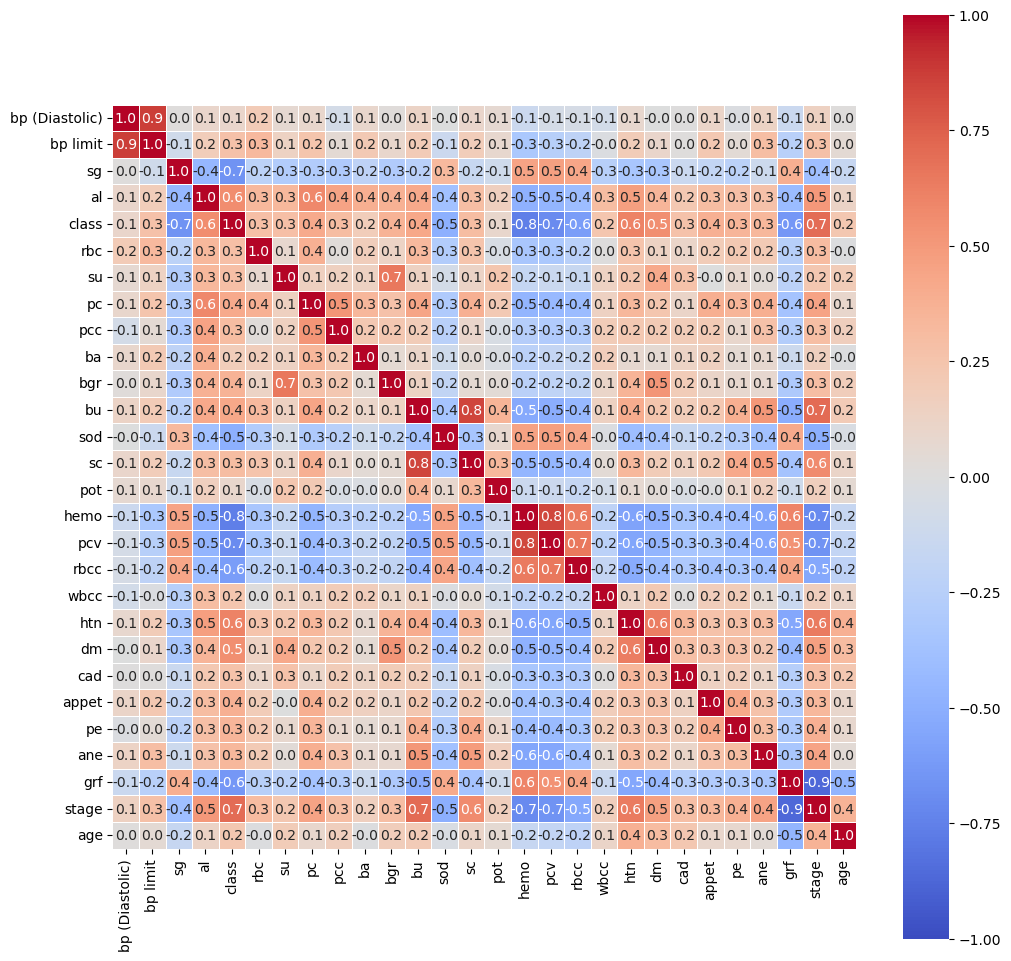

In [43]:
import seaborn as sns
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(12, 12))

sns.heatmap(
    corr_matrix, 
    annot=True,          # Overlays the actual correlation numbers on the cells
    cmap='coolwarm',     # Diverging colormap (blue = negative, red = positive)
    vmin=-1, vmax=1,     # Anchors the colorbar scale from -1 to 1
    fmt=".1f",           # Limits annotations to 2 decimal places
    linewidths=0.5,      # Adds subtle gridlines between cells
    square=True          # Forces cells to be perfectly square shapes
)

In [45]:
stage_corr = corr_matrix['stage'].drop('stage').sort_values(key=abs, ascending=False)
print(stage_corr)

grf              -0.868790
bu                0.709443
hemo             -0.706493
class             0.700282
pcv              -0.661322
htn               0.637410
sc                0.567245
rbcc             -0.546456
al                0.507441
sod              -0.501156
dm                0.463952
pc                0.449010
ane               0.446358
sg               -0.394240
pe                0.380725
age               0.364278
appet             0.333919
rbc               0.307955
pcc               0.291054
bgr               0.290701
cad               0.287741
bp limit          0.280470
su                0.228269
pot               0.167898
wbcc              0.164788
ba                0.159912
bp (Diastolic)    0.145311
Name: stage, dtype: float64


In [47]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_check = df.drop(columns=['stage', 'grf']).select_dtypes(include='number')
X_check = add_constant(X_check)  # VIF calc needs a constant term

vif_data = pd.DataFrame()
vif_data['feature'] = X_check.columns
vif_data['VIF'] = [variance_inflation_factor(X_check.values, i) for i in range(X_check.shape[1])]
vif_data = vif_data[vif_data['feature'] != 'const'].sort_values('VIF', ascending=False)
print(vif_data)

           feature       VIF
2         bp limit  6.681459
1   bp (Diastolic)  5.464671
16            hemo  5.320925
12              bu  5.049604
5            class  4.653055
17             pcv  4.384790
14              sc  4.362270
8               pc  2.636304
4               al  2.624895
20             htn  2.501905
7               su  2.441511
21              dm  2.374200
11             bgr  2.339779
18            rbcc  2.161348
3               sg  2.109981
25             ane  2.049292
9              pcc  1.923996
13             sod  1.775424
15             pot  1.671762
6              rbc  1.643575
24              pe  1.625977
23           appet  1.553217
22             cad  1.476358
10              ba  1.444090
19            wbcc  1.388567
26             age  1.319625


<Axes: >

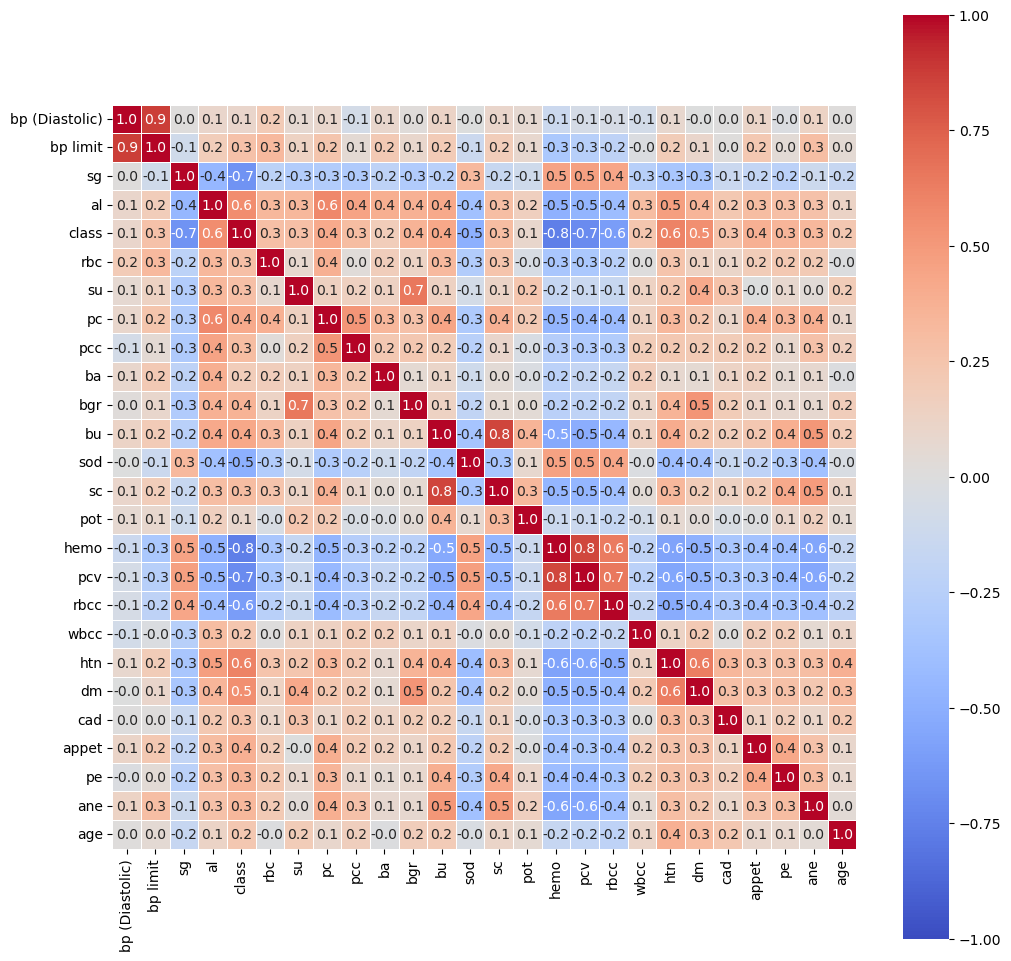

In [49]:
corr_x = X_check.drop(columns='const').corr()
plt.figure(figsize=(12, 12))
sns.heatmap(corr_x, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".1f", linewidths=0.5, square=True)

In [53]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_check2 = df.drop(columns=['stage', 'grf', 'bp limit', 'hemo', 'class']).select_dtypes(include='number')
X_check2 = add_constant(X_check2)  # VIF calc needs a constant term

vif_data2 = pd.DataFrame()
vif_data2['feature'] = X_check2.columns
vif_data2['VIF'] = [variance_inflation_factor(X_check2.values, i) for i in range(X_check2.shape[1])]
vif_data2 = vif_data2[vif_data2['feature'] != 'const'].sort_values('VIF', ascending=False)
print(vif_data2)

           feature       VIF
10              bu  4.741427
12              sc  4.193805
14             pcv  3.045315
6               pc  2.622498
3               al  2.470731
17             htn  2.441328
5               su  2.358000
9              bgr  2.337037
18              dm  2.324091
15            rbcc  2.127706
7              pcc  1.873050
22             ane  1.860177
11             sod  1.723913
2               sg  1.682018
13             pot  1.655558
21              pe  1.603410
4              rbc  1.515005
20           appet  1.486318
19             cad  1.392361
16            wbcc  1.380927
8               ba  1.344993
23             age  1.305180
1   bp (Diastolic)  1.137343


In [55]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

y = df['stage']
X = X_check2.drop(columns='const')  # OrderedModel adds its own intercept-like thresholds, don't pass a constant

model = OrderedModel(y, X, distr='logit')
result = model.fit(method='lbfgs', maxiter=5000, disp=False)
print(result.summary())

                             OrderedModel Results                             
Dep. Variable:                  stage   Log-Likelihood:                -151.98
Model:                   OrderedModel   AIC:                             358.0
Method:            Maximum Likelihood   BIC:                             446.9
Date:                Tue, 15 Sep 2026                                         
Time:                        14:22:41                                         
No. Observations:                 199                                         
Df Residuals:                     172                                         
Df Model:                          23                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
bp (Diastolic)     0.6928      0.335      2.067      0.039       0.036       1.350
sg                 0.0052      0.185    

In [57]:
results_df = pd.DataFrame({
    "coef": result.params,
    "std_err": result.bse,
    "p_value": result.pvalues
})
significant = results_df[results_df["p_value"] < 0.05]
print(significant)

                    coef   std_err       p_value
bp (Diastolic)  0.692826  0.335170  3.872594e-02
bu              2.425575  0.429189  1.590297e-08
sod            -0.471157  0.192553  1.440934e-02
pcv            -0.317271  0.149419  3.372334e-02
age             0.303140  0.091802  9.596335e-04
0/1            -2.792011  1.407486  4.729082e-02
1/2             0.683914  0.156729  1.278944e-05
2/3             0.694092  0.165560  2.760321e-05


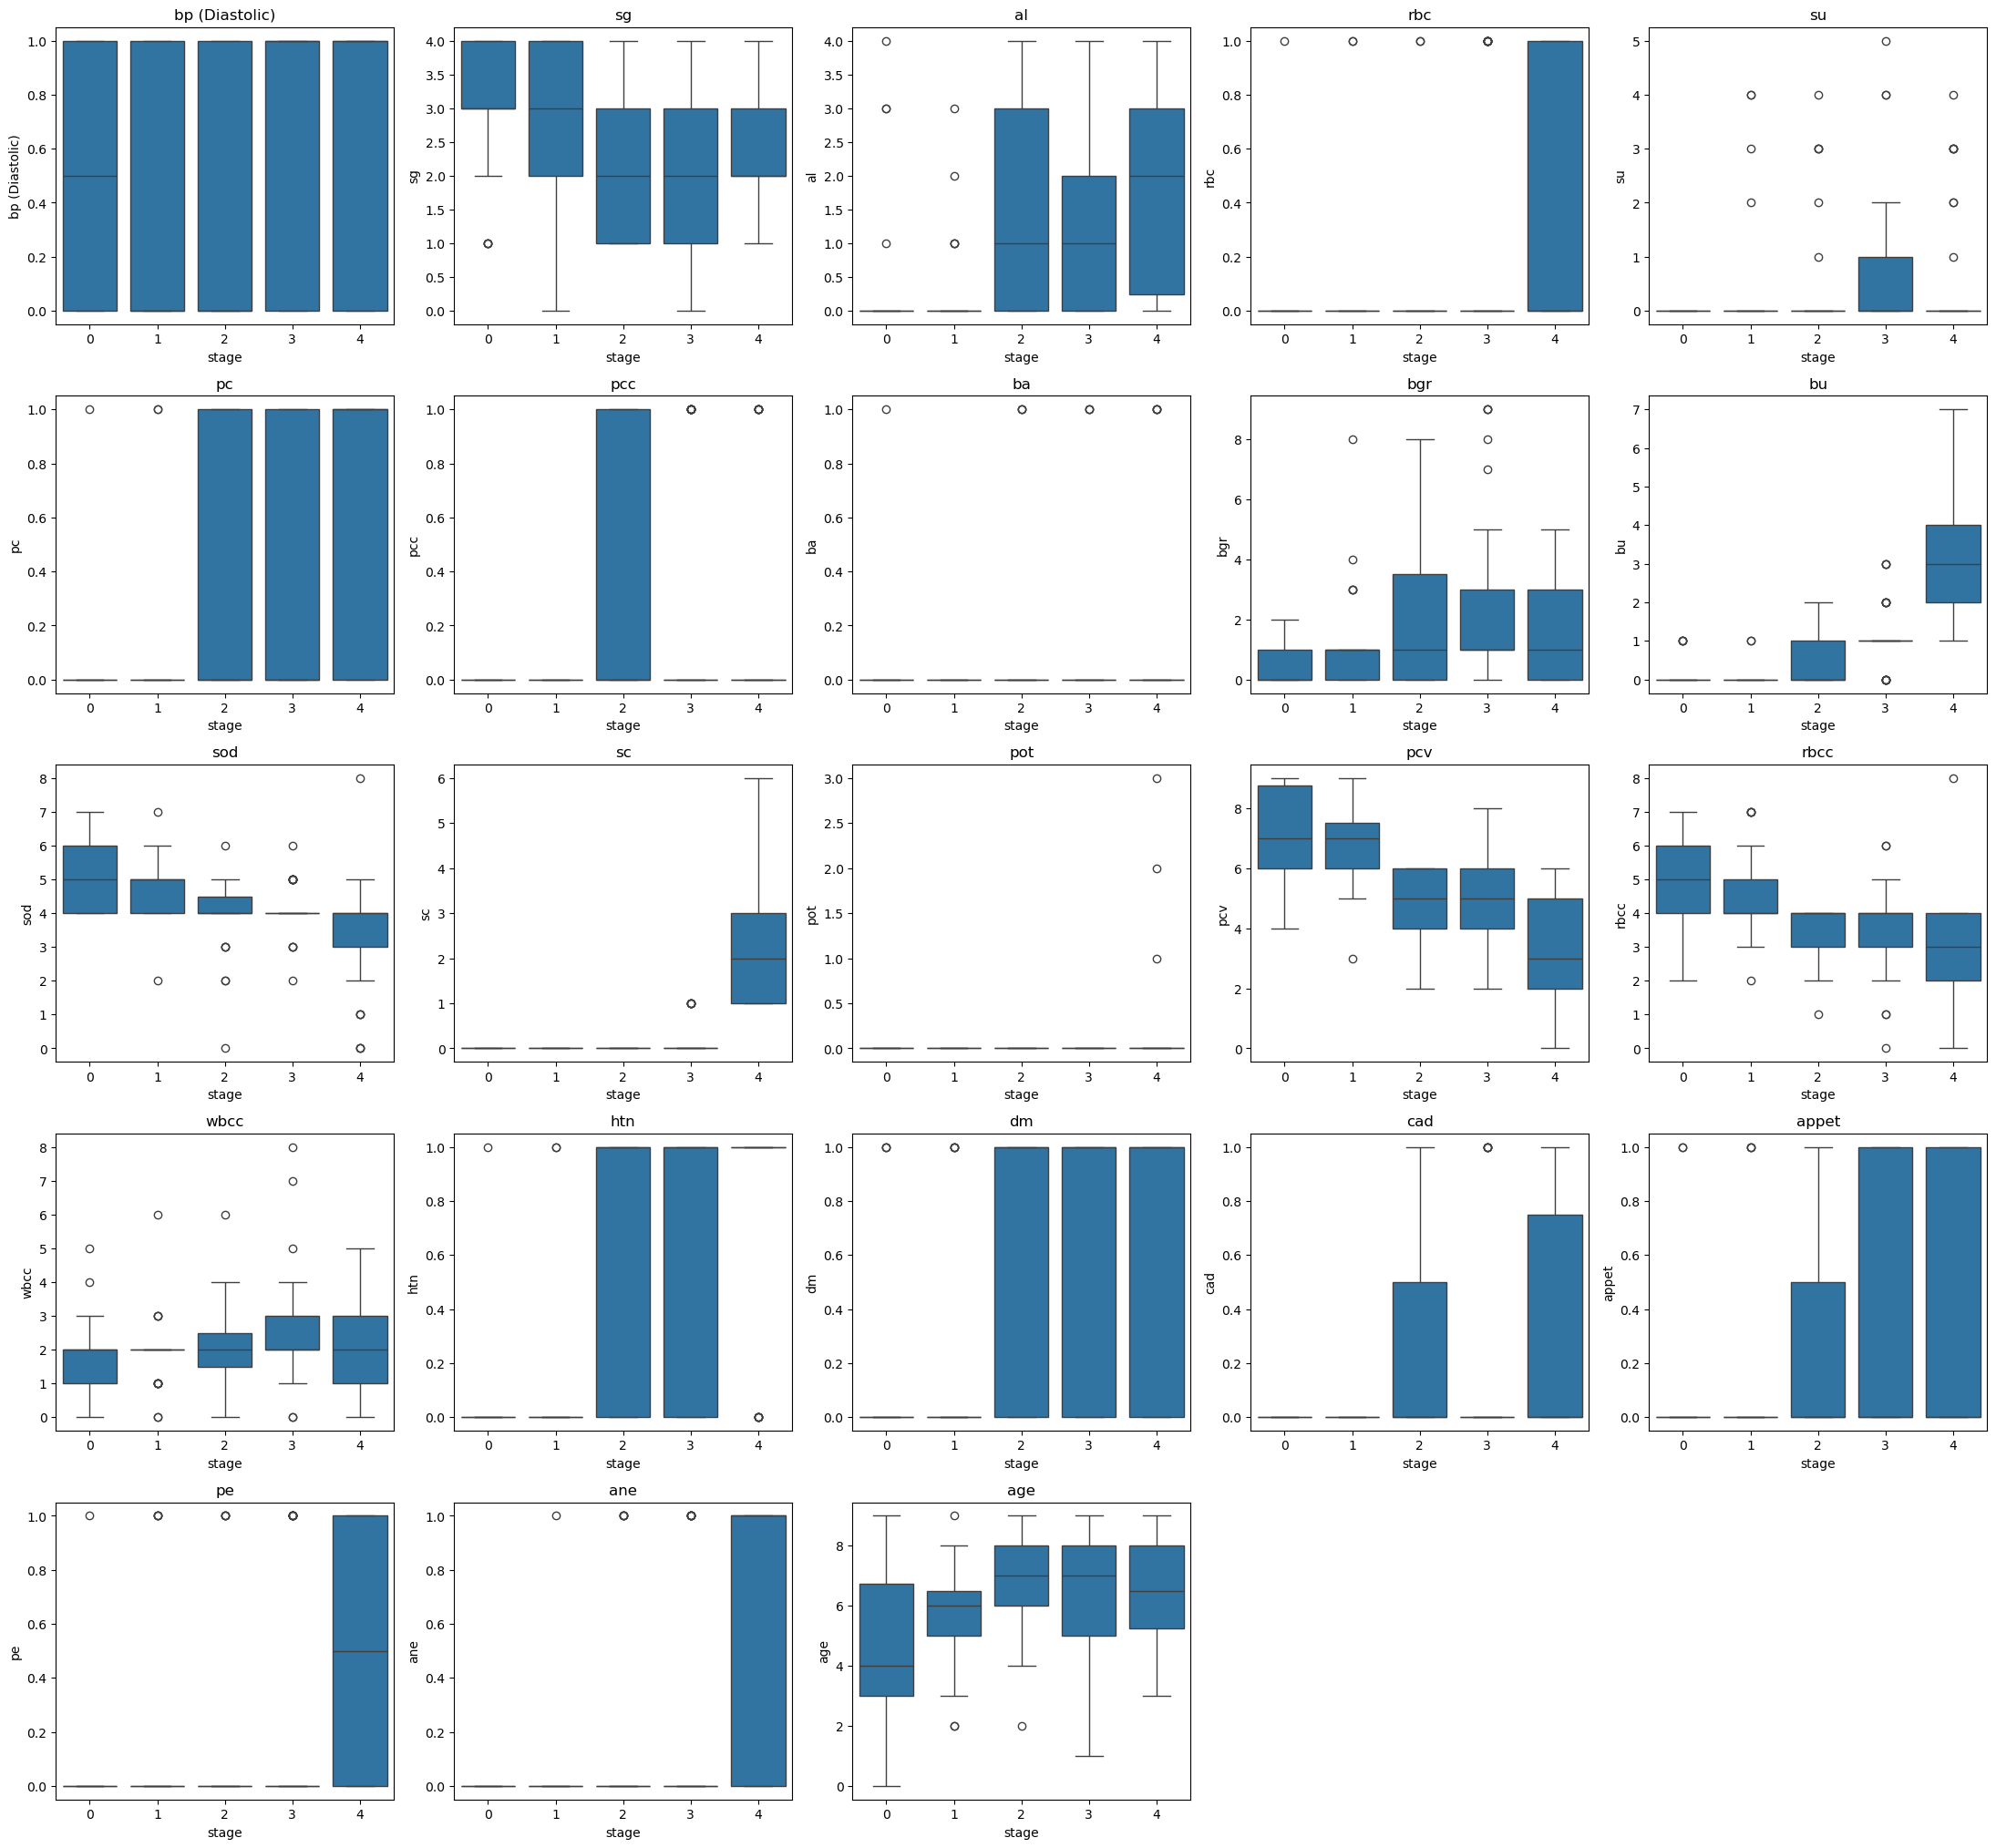

In [59]:
numeric_preds = X_check2.drop(columns='const').columns

fig, axes = plt.subplots(nrows=6, ncols=5, figsize=(22, 24))
axes = axes.flatten()

for i, col in enumerate(numeric_preds):
    sns.boxplot(x=df['stage'], y=df[col], ax=axes[i])
    axes[i].set_title(col)

for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

In [63]:
df['sc'].describe()

count    199.000000
mean       0.386935
std        0.967153
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        6.000000
Name: sc, dtype: float64

In [65]:
df['pot'].describe()

count    199.000000
mean       0.030151
std        0.264184
min        0.000000
25%        0.000000
50%        0.000000
75%        0.000000
max        3.000000
Name: pot, dtype: float64

In [67]:
pd.crosstab(df['sc'], df['stage'])

stage,0,1,2,3,4
sc,,,,,
0,54,35,31,39,0
1,0,0,0,6,16
2,0,0,0,0,8
3,0,0,0,0,4
4,0,0,0,0,4
5,0,0,0,0,1
6,0,0,0,0,1


In [69]:
from scipy import stats

def test_nonlinearity(y, X_base, predictor):
    X_lin = X_base.copy()
    X_quad = X_base.copy()
    X_quad[f'{predictor}_sq'] = X_base[predictor] ** 2

    m_lin = OrderedModel(y, X_lin, distr='logit').fit(method='lbfgs', maxiter=5000, disp=False)
    m_quad = OrderedModel(y, X_quad, distr='logit').fit(method='lbfgs', maxiter=5000, disp=False)

    lr_stat = 2 * (m_quad.llf - m_lin.llf)
    p_value = stats.chi2.sf(lr_stat, df=1)  # 1 extra parameter
    return p_value, m_quad.params[f'{predictor}_sq']

X_base = X_check2.drop(columns='const')
for col in numeric_preds:
    p, coef = test_nonlinearity(y, X_base, col)
    print(f'{col:20s} quad coef={coef: .4f}  LRT p={p:.4f}')

C:\Users\alist\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


bp (Diastolic)       quad coef= 0.3464  LRT p=1.0000
sg                   quad coef=-0.0651  LRT p=0.6651


C:\Users\alist\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


al                   quad coef=-0.3914  LRT p=0.0135
rbc                  quad coef=-0.2408  LRT p=1.0000
su                   quad coef=-0.3738  LRT p=0.1300


C:\Users\alist\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


...

dm                   quad coef=-0.0013  LRT p=0.9934
cad                  quad coef=-0.4494  LRT p=0.9874


C:\Users\alist\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


appet                quad coef= 0.5063  LRT p=1.0000
pe                   quad coef= 0.0756  LRT p=1.0000


C:\Users\alist\anaconda3\Lib\site-packages\statsmodels\base\model.py:595: HessianInversionWarning: Inverting hessian failed, no bse or cov_params available
  warnings.warn('Inverting hessian failed, no bse or cov_params '


ane                  quad coef=-0.3359  LRT p=1.0000
age                  quad coef=-0.0639  LRT p=0.0734


In [73]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

y = df['stage']
predictors = ['bp (Diastolic)', 'bu', 'sod', 'pcv', 'age']
X = df[predictors]

model = OrderedModel(y, X, distr='logit')
result = model.fit(method='lbfgs', maxiter=5000, disp=False)
print(result.summary())

                             OrderedModel Results                             
Dep. Variable:                  stage   Log-Likelihood:                -181.99
Model:                   OrderedModel   AIC:                             382.0
Method:            Maximum Likelihood   BIC:                             411.6
Date:                Tue, 15 Sep 2026                                         
Time:                        15:00:40                                         
No. Observations:                 199                                         
Df Residuals:                     190                                         
Df Model:                           5                                         
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
bp (Diastolic)     0.5653      0.300      1.885      0.059      -0.023       1.153
bu                 2.2362      0.288    

In [75]:
print(result.pvalues)

bp (Diastolic)    5.947128e-02
bu                8.284856e-15
sod               7.813704e-05
pcv               1.209321e-05
age               4.758582e-05
0/1               3.067408e-05
1/2               1.607678e-04
2/3               7.772546e-04
3/4               2.202574e-17
dtype: float64
